# 05 - Lithology & the Multi-Mineral Solver

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/05_lithology_and_mineral_solver.ipynb)

**Part A - Petrophys Curriculum**

Rock is a mixture. A gamma-ray or a single porosity log tells you *how much* of
something is there, but not *what* the mineral framework is. This lesson builds
up lithology interpretation in two stages:

1. **Qualitative** - neutron-density and PEF crossplots, where each mineral plots
   in a known place, so eyeballing the point cloud already tells you sand vs.
   limestone vs. dolomite.
2. **Quantitative** - the least-squares **multi-mineral solver**
   (`petrophys.interpretation.lithology.MultiMineralSolver`) that turns the same logs into
   *mineral volume fractions* at every depth.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals
- Read a **neutron-density crossplot** and a **PEF (photoelectric) crossplot** and
  place quartz, calcite and dolomite on them from first principles.
- Understand why the solver carries the photoelectric log as `U = PEF x rho`
  (volumetric photoelectric cross-section): `U` mixes volumetrically, so it is a
  valid linear-equation row, and its density factor is what separates calcite
  from anhydrite.
- Write the multi-mineral response system `A x = b` and know what each row and
  each unknown means.
- Appreciate the key design choice: porosity is taken from the porosity step where
  the neutron is logged, and solved as an extra unknown where it is not.
- Run the solver with `pp.interpret`, plot a **stacked mineral-volume track**, and
  check it against the vendor lithology log.
- Replace a mineral endpoint with a value from the well's own rock
  (`mineral_endpoints`).

## Why this matters
Every downstream petrophysical answer - porosity, water saturation, permeability,
net pay - needs a matrix (grain) property: matrix density `rho_ma`, matrix sonic
slowness, etc. If you *assume* a sandstone matrix in a limestone, your porosity is
wrong by several porosity units, and the error propagates into saturation and
volumetrics.

The classic workaround is a crossplot: read the lithology, pick the matrix, then
compute porosity. The multi-mineral solver does better - it solves the mineral
mix from all available logs at once, and can solve porosity *simultaneously*, so
there is no circular "assume-a-matrix-to-get-porosity" step.

### Prerequisites
This lesson assumes lessons **01-04** (loading a well, plotting it, clay volume,
porosity). `pp.interpret` computes the clay volume and porosity the solver needs.

Teaching well: **15_9-14** (Norwegian North Sea, quadrant 15, Sleipner area). It
carries the full lithology tool string we need - `RHOB`, `NPHI`, `PEF` and `DTC` -
and it runs from quartz-rich clastics through an Upper Cretaceous chalk section (about
2700-3000 m), then marl and argillaceous limestone, into deeper clastics from about
3200 m to TD (3575 m), so both the crossplots and the solver have something interesting to say.

In [2]:
import pandas as pd
import petrophys as pp

pd.set_option("display.max_colwidth", None)   # show the trace's decisions in full
well = pp.read(pp.sample("15_9-14"))
well

Well(15/9-14, curves=15, samples=20311)

## 1. Mineral endpoints - the physics we anchor to

The solver and the crossplots both stand on a small table of **tool responses for
pure minerals**. `mineral_properties` returns, for each mineral:

| key | property | tool |
|---|---|---|
| `density` | matrix bulk density (g/cc) | density (RHOB) |
| `nphi` | apparent neutron porosity of the pure matrix (v/v) | neutron (NPHI) |
| `pef` | photoelectric factor (b/e) | litho-density (PEF) |
| `slowness` | matrix sonic slowness (us/ft) | sonic (DTC) |
| `u` | volumetric photoelectric cross-section `U = PEF x density` (b/cm3) | litho-density |

`U` is the form the solver actually uses: unlike raw PEF, `U` is (to a good
approximation) **volumetrically additive**, so it can sit in a linear mixing
equation next to density and neutron.

In [3]:
from petrophys.interpretation.lithology import mineral_properties

minerals = ["quartz", "calcite", "dolomite", "anhydrite", "clay", "water"]
pd.DataFrame({name: mineral_properties(name) for name in minerals}).T

,density,slowness,nphi,pef,u
quartz,2.65,55.5,-0.02,1.80,4.80
calcite,2.71,47.6,0.00,5.10,13.80
dolomite,2.87,43.5,0.02,3.10,9.00
anhydrite,2.96,50.0,-0.02,5.00,14.90
clay,2.65,80.0,0.35,3.70,9.81
water,1.00,189.0,1.00,0.36,0.36


**Read this table like an interpreter:**

- **Density** separates dolomite (2.87) and anhydrite (2.96) from quartz (2.65)
  and calcite (2.71), but quartz vs. calcite is only 0.06 g/cc apart - too close
  to call on density alone.
- **PEF** is the classic lithology flag: quartz 1.8, dolomite 3.1, calcite 5.1.
  It is nearly independent of porosity, which is why it is so powerful.
- **U = PEF x rho** is the same contrast in a volumetrically additive form:
  quartz 4.8, dolomite 9.0, calcite 13.8, anhydrite 14.9 b/cm3. The
  quartz-calcite ratio is essentially the same as in raw PEF (about 2.9x vs 2.8x) -
  the point of `U` is not extra spread. It earns its place because it *mixes
  linearly* with volume fractions (raw PEF does not, so it cannot be a solver
  row), and because its density factor pulls anhydrite (14.9) away from calcite
  (13.8), which raw PEF barely separates (5.0 vs 5.1).

## 2. Neutron-density crossplot

On an N-D crossplot, RHOB (inverted, high density down) is plotted against NPHI.
Pure minerals sit at the **zero-porosity matrix points**; adding water porosity
drives a point up-and-right toward the water point (NPHI=1, rho=1). So each
mineral has its own *porosity line* fanning out from its matrix point.

The crossplot needs all the lithology logs at once, so first find the interval
where `RHOB`, `NPHI`, `PEF` and `DTC` are all recorded:

In [4]:
logs = well.to_dataframe().dropna(subset=["RHOB", "NPHI", "PEF", "DTC"])
logs["DEPTH"].agg(["min", "max", "count"])

min        480.37210
max       3019.96484
count    16665.00000
Name: DEPTH, dtype: float64

PEF is recorded from about 480 m down to 3020 m, while RHOB and DTC continue
deeper, so the lithology work below stays inside 480-3020 m. Above 1371 m the
hole is 17 1/2 in and wider, and the density reads a flat 2.00 g/cc over long
stretches there: the pad does not keep contact with the wall. The crossplots
therefore use the 12 1/4 in section, 1371-3020 m. The points are
coloured by GR: low GR (clean, sand-prone or carbonate) vs. high GR (shaly).

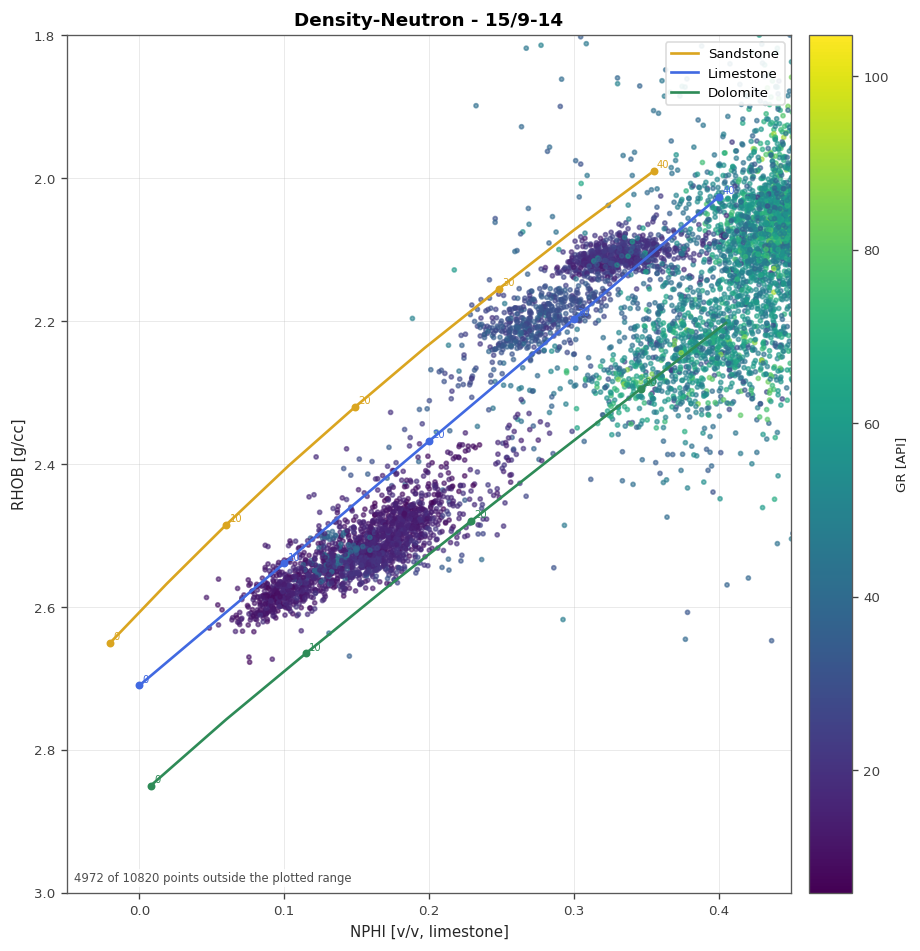

In [5]:
pp.crossplot(well, "NPHI", "RHOB", top=1371, bottom=3020)

#### Crossplot interpretation

The dense, low-GR cluster at low NPHI and high RHOB lies just right of the limestone
line, between it and the dolomite line: the chalk. The porous, low-GR sands plot at
higher NPHI and lower RHOB, about a third between the sandstone and limestone lines and
the rest right of the limestone line, where clay and the neutron's matrix response move
a sand. The plotter's window
ends at NPHI 0.45, and the note on the chart counts the points beyond it: about
half of the samples. Those are the shales. Clay-bound water raises the neutron
reading, so the shale cloud lies to the right of (below) the matrix lines and
runs off the chart.

## 3. PEF crossplot (RHOB vs PEF)

Because PEF is almost porosity-independent, a RHOB-vs-PEF plot separates the
**mineralogy** cleanly: vertical bands of PEF pin the lithology while density
scatters with porosity. Quartz (1.8 b/e), dolomite (3.1) and calcite (5.1) fall
into distinct PEF columns.

Each mineral line runs from its matrix point at zero porosity toward water,
ticked every 10 % porosity; anhydrite is shown as a point.

One practical wrinkle: raw PEF picks up **spikes in bad hole** (barite-loaded mud
reads PEF in the hundreds). The chart keeps PEF at 0-8 b/e and counts the points
beyond it in a note, rather than letting one bad sample crush the mineral bands -
and we quote the **median** PEF (spike-resistant), not the mean.

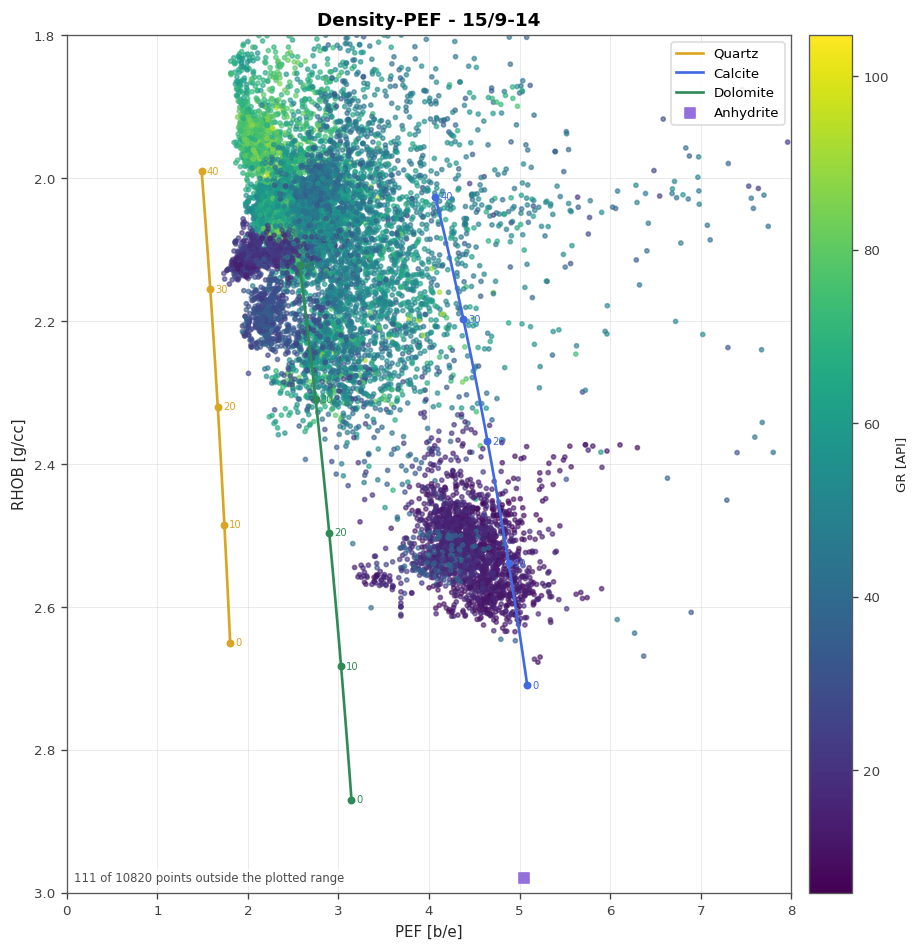

In [6]:
pp.crossplot(well, "PEF", "RHOB", top=1371, bottom=3020)

In [7]:
side = logs["DEPTH"].map(lambda depth: "above 2750 m" if depth <= 2750 else "below 2750 m")
logs.groupby(side)["PEF"].describe()

,count,mean,std,min,25%,50%,75%,max
DEPTH,,,,,,,,
above 2750 m,14893.0,2.808915,4.373836,-33.906,2.023,2.291,2.834000,201.000
below 2750 m,1772.0,4.425709,0.463963,2.525,4.199,4.441,4.699822,6.301


#### PEF interpretation

Above 2750 m the median PEF, about 2.3 b/e, is closest to the quartz response of
1.8 b/e: predominantly quartz-rich clastics with some clay. Below 2750 m the median
rises to about 4.4 b/e and approaches the calcite response of 5.1 b/e: the chalk,
which lies on the calcite line of the crossplot between 10 and 20 % porosity.
The minimum and maximum of the shallower interval, a negative PEF and one of
about 200 b/e, are no mineral at all: they are bad-hole spikes, and the median
ignores them. Section 5 solves the carbonate window for mineral volumes.

## 4. The multi-mineral response system

Every log is a **linear volumetric mixing** of the components in the rock. For a
rock made of mineral volumes $V_1 \dots V_n$, porosity $\phi$ and clay $V_{cl}$,
each tool reading is:

$$\text{tool} = \sum_i V_i \cdot t_i \;+\; \phi \cdot t_{fl} \;+\; V_{cl}\cdot t_{cl}$$

where $t_i$ is that tool's response for pure component $i$. Writing one equation
per tool (plus a **unity** equation that forces the volumes to close) gives a
linear system $A\,\mathbf{x} = \mathbf{b}$:

$$
\begin{aligned}
\text{Unity:}   & \quad V_1 + \dots + V_n + \phi              &= 1 - V_{cl}\\
\text{Density:} & \quad V_1\rho_1 + \dots + \phi\,\rho_{fl}   &= \rho_{log} - V_{cl}\rho_{cl}\\
\text{Neutron:} & \quad V_1 N_1 + \dots + \phi\,N_{fl}        &= N_{log} - V_{cl}N_{cl}\\
\text{U:}       & \quad V_1 U_1 + \dots + \phi\,U_{fl}        &= U_{log} - V_{cl}U_{cl}\\
\text{Sonic:}   & \quad V_1 D_1 + \dots + \phi\,D_{fl}        &= D_{log} - V_{cl}D_{cl}\\
\end{aligned}
$$

with $U = \text{PEF}\times\rho$. The clay term is computed beforehand (from GR and
the other clay indicators) and moved to the right-hand side, so only the minerals
and $\phi$ remain as unknowns. The system is solved with non-negative least
squares, which keeps all volumes >= 0.

### The key design choice: is porosity an unknown or an input?
- Where the neutron is logged, porosity comes from the workflow's porosity step as
  a *fixed input*, which has already read the density and neutron. The solver then
  solves only for the minerals, and leaves a sample unsolved when the minerals
  cannot fill the remaining volume $1 - V_{cl} - \phi$ to within 0.05 (the closure
  gate).
- Where it is not, a porosity from density alone would need an assumed matrix
  density, so $\phi$ goes into the **unknown vector** $\mathbf{x}$ next to the
  minerals, solved from density, $U$ and closure: two minerals (quartz and calcite,
  or calcite and dolomite in carbonate) and porosity, under the same closure gate.

The rows carry different units (v/v, g/cm$^3$, b/cm$^3$, us/ft), so each row is
divided by its nominal one-sigma tool uncertainty: 0.01 for unity, 0.02 g/cm$^3$
for density, 0.02 v/v for neutron, 0.5 b/cm$^3$ for $U$ and 2 us/ft for sonic.
Every residual is then measured in units of tool error: the weighted least squares
of Mayer and Sibbit (1980, SPE 9341) and Quirein et al. (1986, SPWLA 27th
Symposium).

## 5. Solve the well and build a mineral-volume track

`pp.interpret` runs the mineral solve as one step of the full interpretation and
writes the volumes `VQUAR`, `VCALC`, `VDOLO` and `VANHY` (quartz, calcite,
dolomite, anhydrite) next to the clay volume `VCL` and porosity `PHIE`. We focus on
the carbonate window **2750-3020 m**: the carbonate section the crossplots pointed
at, with PEF live all the way down. The plot puts the vendor lithology log of
15/9-14 (`LITHOLOGY_GEOLINK`) beside the solved volumes, an independent
interpretation to check the solve against.

[repository]\src\petrophys\workflow\dynamic_workflow.py:5743: DataQualityWarning: DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.
  standardize_curves(
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1169: DataQualityWarning: RSHA: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1169: DataQualityWarning: RXO: 6 of 4059 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.
  return standardizer.standardize(well)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:1169: DataQualityWarning: RMED: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed

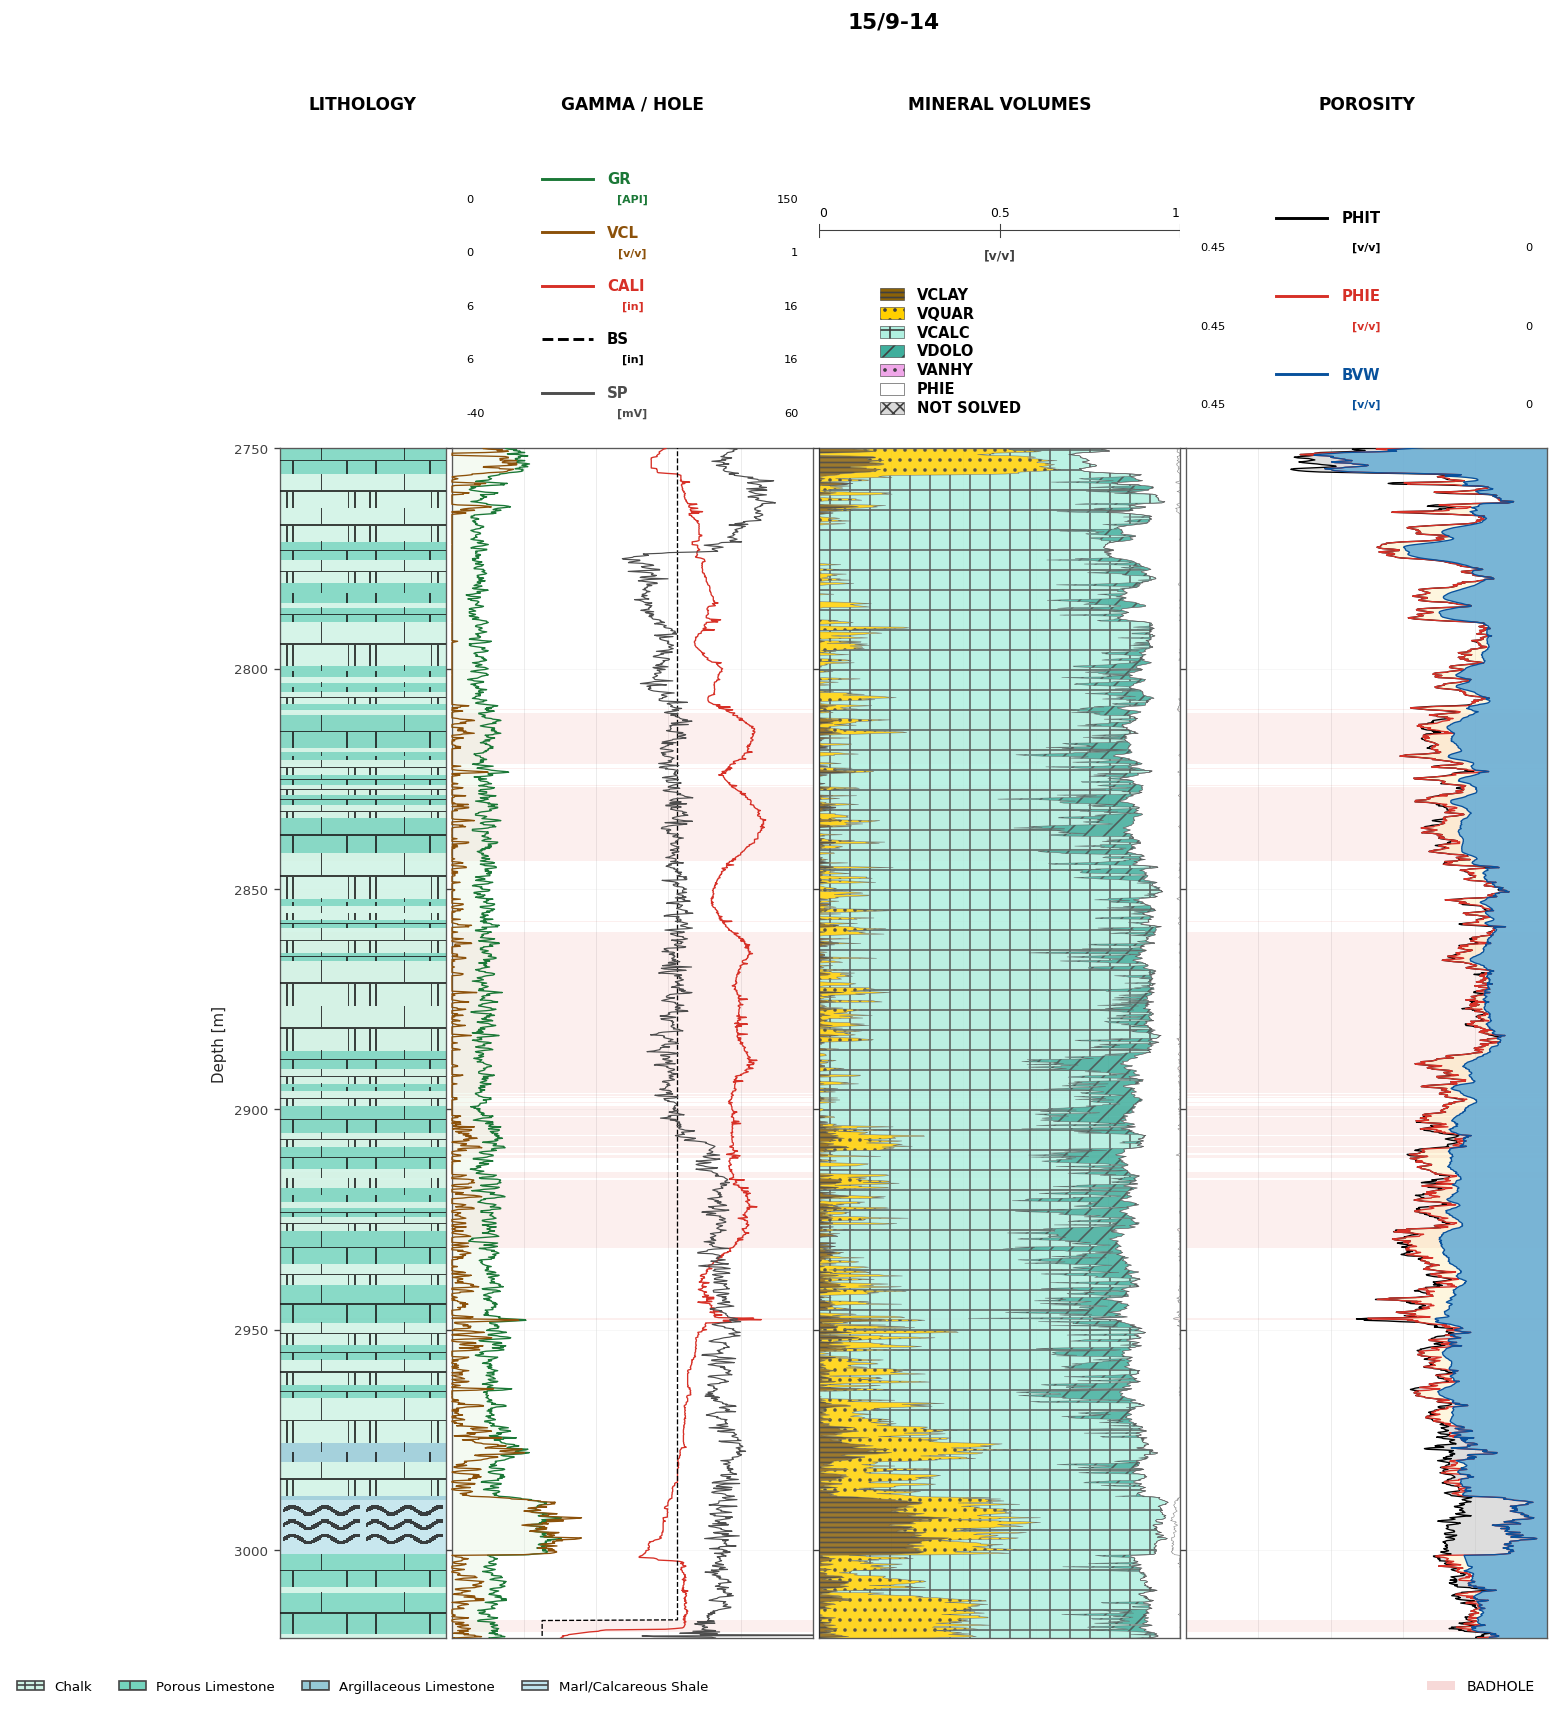

In [8]:
result = pp.interpret(well)
pp.plot(result, top=2750, bottom=3020,
        tracks=["LITHOLOGY", "GAMMA / HOLE", "MINERAL VOLUMES", "POROSITY"])

The interpretation printed `DataQualityWarning`s while it read the logs, and it
keeps every message about what it had to work around in `result.warnings`:

In [9]:
result.warnings

['Held readings, one value repeated exactly over ten samples or more: RXO 3.135 over 3555.8-3573.18 m (116 samples), GR 94.188 over 3564.79-3573.18 m (57 samples), NPHI 0.23975 over 3573.18-3575.31 m (16 samples), NPHI 0.23926 over 3568.3-3570.13 m (14 samples), RDEP 2.041 over 3568.15-3569.67 m (12 samples) and 3 more. A tool that stopped reading, or a log padded to a depth, holds its last value while the other logs change; check these against the other logs before using them.',
 'DTE: 20181 of 20181 samples are outside the plausible DTE range 20 to 600 us/ft and were removed.',
 "RSHA: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.",
 "RXO: 6 of 4059 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed.",
 "RMED: 13 of 20295 samples sit at the curve's maximum 2000 ohm.m, a tool or computation ceiling rather than a reading, and were removed

- **`DTE`**, this file's shear sonic, is labelled us/ft, but its values are in the
  tens of millions, while a shear slowness is at most a few hundred us/ft, so every
  sample is screened out (and the plot leaves it out too). Nothing here uses
  `DTE`; the solver uses the compressional sonic `DTC`.
- **`RSHA`, `RXO`, `RMED`** have a few samples stuck at 2000 ohm.m, a tool ceiling,
  which are removed.
- The header has **no bottom-hole temperature or Rw**, so the temperature profile
  follows an assumed gradient and Rw comes from the SP. Neither affects the mineral
  solve; lesson 06 covers both.
- **Bad hole**: the caliper and density-correction flag removes net pay. Again
  outside this lesson's subject.

On your own data, treat each message as a prompt to check that curve or setting,
not as noise to silence. Having read them, we hide the repeated log-screening
warnings of the next runs:

In [10]:
import warnings

warnings.filterwarnings("ignore", message=r"(DTE|RSHA|RXO|RMED): ")

The mean volumes over the window, and the lithology step's own account of how many
samples it solved:

In [11]:
result.statistics(["VQUAR", "VCALC", "VDOLO", "VANHY", "VCL", "PHIE"], top=2750, bottom=3020).round(3)

,unit,samples,mean,p10,median,p90
VQUAR,v/v,1772,0.092,0.000,0.053,0.248
VCALC,v/v,1772,0.690,0.503,0.703,0.866
VDOLO,v/v,1772,0.069,0.000,0.047,0.179
VANHY,v/v,1772,0.000,0.000,0.000,0.000
VCL,v/v,1772,0.030,0.000,0.000,0.078
PHIE,v/v,1772,0.118,0.073,0.118,0.161


In [12]:
result.step("lithology").decisions

['Mineral volumes computed; the input lithology is kept, and LITHO is not inferred',
 'PEF screened for plausibility; without PEF the minerals are solved from RHOB and NPHI (sonic is used beside PEF, not in its place)',
 'Clastic minerals solved per sample from the logs, with a check that minerals, clay and porosity add up to one',
 'Equation rows weighted by nominal one-sigma tool uncertainty: unity 0.01 v/v, rhob 0.02 g/cm3, nphi 0.02 v/v, u 0.5 b/cm3, dt 2 us/ft',
 'Multi-mineral solved 19634/20311 samples; QC flagged 677']

#### Interpretation and caveats

The solved track is predominantly calcite, which agrees with the vendor
lithology at the level of rock family: chalk and porous limestone dominate the
lithology column, and the solve averages calcite near 0.69 over the window, with
porosity about 0.12 and little clay. Every sample in the window was solved.

The mineral split does not agree in detail. The solve puts about 7 % dolomite
into intervals the vendor log calls chalk and porous limestone, most of it below
about 2830 m, and the vendor log does not support it. Quartz rises at the top of
the window and below about 2960 m, around the argillaceous limestone and the marl
at about 2990 m, where quartz and clay trade off against each other.
Calcite and dolomite differ mainly in density (2.71 vs 2.87 g/cc) and $U$, so a
porosity or density error moves volume between them.

## 6. Mineral endpoints as an interpretation setting

The workflow's clastic mineral solve has its own endpoint table, close to the one in
section 1. `mineral_endpoints` replaces any of its values: a mapping of mineral
(`quartz`, `calcite`, `dolomite`, `anhydrite`, `clay`) or pore fluid (`water`) to any of
`rhob`, `nphi`, `pef`, `u` and `dt`, e.g. `{"quartz": {"nphi": -0.04}}` for a neutron tool
whose chart puts quartz there. Porosity keeps `rho_fl` and `dt_fl`. An unknown mineral or
key raises a `ValueError` that names the allowed ones. In a LAS header each value is a
`<MINERAL>_<PROPERTY>` parameter - `QUARTZ_RHOB`, `CLAY_NPHI`, `WATER_NPHI` - and a value
passed to `interpret` wins over the header.

The clay point is the endpoint with the clearest local source. The workflow's PHIE
excludes the clay-bound water, so the clay term has to carry that water: a wet-clay,
or shale, point, which the well's own shale gives. In the clastic section above the
chalk (2400-2725 m), the median log readings of each vendor lithology class are:

In [13]:
from petrophys.visualization.log_viewer import LITHOLOGY_CODE_LABELS

clastic = well.to_dataframe().query("2400 <= DEPTH <= 2725")
clastic.groupby("LITHOLOGY_GEOLINK")[["RHOB", "NPHI"]].agg(["median", "count"]).rename(LITHOLOGY_CODE_LABELS).round(2)

RHOB         NPHI      
                  median count median count
LITHOLOGY_GEOLINK                          
Sandstone           2.20   187   0.27   187
Silty Sand          2.19   299   0.28   299
Sandy Silt          2.18   335   0.36   335
Silt                2.19   793   0.40   793
Shaly Silt          2.21   358   0.41   358
Silty Shale         2.28    51   0.43    51
Calcareous Cement   2.34     9   0.33     9
Cinerite            2.25   101   0.38   101

The shaliest class, Silty Shale, reads RHOB 2.28 g/cm3 and NPHI 0.43 v/v, against
the table's clay point of 2.65 and 0.35. Pass it as the clay endpoint and compare
the solved samples (`samples`) and the mean volumes over 2400-2725 m:

In [14]:
volumes = ["VQUAR", "VCALC", "VDOLO", "VANHY"]
shale_clay = pp.interpret(well, mineral_endpoints={"clay": {"rhob": 2.28, "nphi": 0.43}})
runs = {"built-in clay": result, "shale-point clay": shale_clay}
pd.concat({name: r.statistics(volumes, top=2400, bottom=2725)[["samples", "mean"]]
           for name, r in runs.items()}, axis=1).round(3)

built-in clay        shale-point clay       
            samples   mean          samples   mean
VQUAR          2040  0.335             2093  0.337
VCALC          2040  0.079             2093  0.076
VDOLO          2040  0.006             2093  0.014
VANHY          2040  0.000             2093  0.000

With the well's own shale point, about 50 more of the 2133 samples in the
interval pass the closure gate (2093 instead of 2040), and the mean volumes move
by no more than a hundredth: quartz stays near 0.34, calcite near 0.08. An endpoint
from the well's own rock is the better-founded choice, but check the volumes it
gives against independent lithology: the vendor log has calcareous cement in only
9 samples of this interval, so the 0.08 of calcite is an overestimate either way.

## Pitfalls & parameter choices
- **Clay endpoints drive everything.** `Vcl` is subtracted from every right-hand
  side, so a bad GR clean/clay pick biases the whole solution. Set `gr_min` and
  `gr_max` from the formation you evaluate when the automatic picks do not fit it.
- **Enough equations for the mineral set.** The solver needs at least (n_minerals
  + 1) independent rows to resolve n minerals plus porosity. Where PEF is missing,
  or set aside as implausible (barite mud), it solves fewer minerals; where too few
  logs are live the sample stays unsolved.
- **PEF over sonic for carbonates.** `U = PEF x rho` separates calcite/dolomite/
  anhydrite far better than sonic; without PEF the calcite/dolomite split is weak.
- **Watch the QC counts.** The lithology step reports solved and QC-flagged
  samples (bad hole, gas effect, unmodeled minerals). Do not trust volumes there
  blindly.
- **Non-uniqueness.** More minerals than independent logs -> the system is
  underdetermined and the solver picks *a* non-negative answer, not *the* answer.
  Keep the mineral set as small as the geology allows.
- **Domain matters.** `lithology="carbonate"` switches to the carbonate solve,
  calcite and dolomite from bulk density and closure, which suits a limestone or
  dolomite reservoir better than the clastic four-mineral set.

## Recap
- Minerals occupy fixed positions on N-D and PEF crossplots; the solver carries
  the photoelectric signal as `U = PEF x rho` because `U` mixes volumetrically
  (a valid linear-equation row, unlike raw PEF) and its density factor separates
  calcite (13.8) from anhydrite (14.9 b/cm3).
- The multi-mineral solver writes one linear equation per tool (unity, density,
  neutron, U, sonic) and solves them with non-negative least squares.
- `pp.interpret` runs it and writes `VQUAR`, `VCALC`, `VDOLO`, `VANHY`;
  `pp.plot(..., tracks=["LITHOLOGY", "MINERAL VOLUMES"])` checks them against a
  lithology log.
- Porosity is taken from the porosity step where the neutron is logged and solved
  with the minerals where it is not; `mineral_endpoints` replaces endpoints with
  values from the well's own rock.

## Try it yourself
> **Exercise 1.** Interpret 15/9-14 with `lithology="carbonate"` and compare its
> `VCALC` and `VDOLO` with the default run over 2750-3020 m. How many samples does
> the carbonate solve leave unsolved, and why (read the lithology step of the trace)?
>
> **Exercise 2.** Run `pp.interpret(well, lithology_source="computed")`, which
> ignores the vendor lithology log, and plot the `LITHOLOGY` track it infers next to
> the `MINERAL VOLUMES` track. Where does the inferred lithology disagree with the
> vendor log?
>
> **Exercise 3.** Change the quartz neutron endpoint with
> `mineral_endpoints={"quartz": {"nphi": -0.04}}`. How much do the quartz and
> calcite volumes of the clastic interval move?

## What's next
Continue with **06 - Formation Water & Environmental Corrections**, where we work
out Rw, Rmf and the temperature profile - the inputs the saturation calculation in
lesson 07 will need.